## Load data set

In [4]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
ORDER = ["Seattle metro", "Eastern WA", "Other"]
COLORS = {"Seattle metro": "C0", "Eastern WA": "C3", "Other": "gray"}

df = pd.read_csv("cleaned_unemployment_rate.csv", dtype={"fips": str})
wide = df.pivot(index="county", columns="year", values="unemployment_rate")

## Overview and data quality

In [7]:
print("Shape:", df.shape)
print("Counties:", df["fips"].nunique(), "| Years:", df["year"].min(), "-", df["year"].max())
print("Balanced panel (every county has every year):", df.groupby("fips")["year"].nunique().eq(10).all())
print("Duplicate county-years:", df.duplicated(["fips", "year"]).sum())
print("FIPS all 5 characters:", df["fips"].str.len().eq(5).all())
print("Missing values:", int(df.isna().sum().sum()))
print("\nCounties per region:"); print(df.drop_duplicates("fips")["region"].value_counts().to_string())
df["unemployment_rate"].describe().round(2)

Shape: (390, 5)
Counties: 39 | Years: 2015 - 2024
Balanced panel (every county has every year): True
Duplicate county-years: 0
FIPS all 5 characters: True
Missing values: 0

Counties per region:
region
Other            29
Eastern WA        7
Seattle metro     3


count    390.00
mean       5.96
std        1.62
min        2.80
25%        4.80
50%        5.70
75%        6.90
max       11.20
Name: unemployment_rate, dtype: float64

The panel is balanced (39 counties x 10 years = 390 rows), with no missing values or duplicates and valid 5-digit FIPS codes, so it is ready to merge with the housing data.

## Distribution of unemployment rates

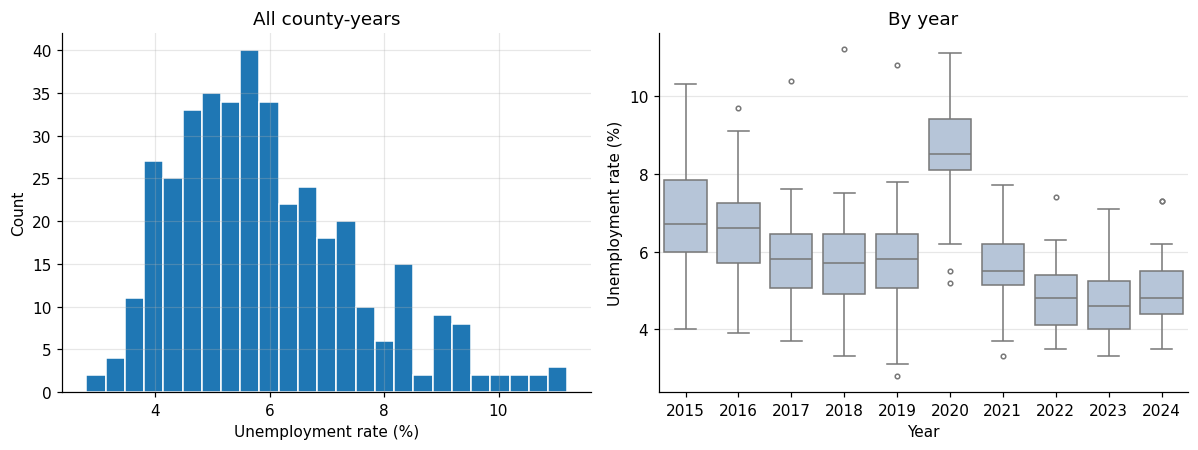

Skewness: 0.84


,mean,median,min,max,std
year,,,,,
2015,6.93,6.7,4.0,10.3,1.49
2016,6.56,6.6,3.9,9.7,1.31
2017,5.83,5.8,3.7,10.4,1.25
2018,5.76,5.7,3.3,11.2,1.33
2019,5.82,5.8,2.8,10.8,1.45
2020,8.60,8.5,5.2,11.1,1.29
2021,5.65,5.5,3.3,7.7,0.94
2022,4.80,4.8,3.5,7.4,0.88
2023,4.70,4.6,3.3,7.1,0.87


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].hist(df["unemployment_rate"], bins=25, edgecolor="white")
axes[0].set(title="All county-years", xlabel="Unemployment rate (%)", ylabel="Count")
sns.boxplot(data=df, x="year", y="unemployment_rate", ax=axes[1], color="lightsteelblue", fliersize=3)
axes[1].set(title="By year", xlabel="Year", ylabel="Unemployment rate (%)")
plt.tight_layout(); plt.show()
print("Skewness:", round(df["unemployment_rate"].skew(), 2))
df.groupby("year")["unemployment_rate"].agg(["mean", "median", "min", "max", "std"]).round(2)

## Statewide trend (simple average of the 39 counties)
This is an unweighted average, so each county counts equally regardless of size. It describes the typical county, not the statewide rate.

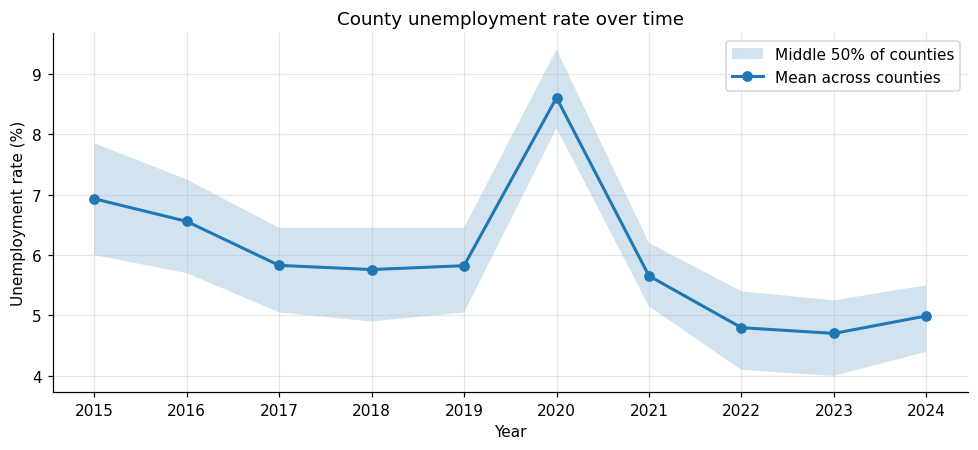

In [14]:
yr = df.groupby("year")["unemployment_rate"]
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.fill_between(yr.mean().index, yr.quantile(0.25), yr.quantile(0.75), alpha=0.2, label="Middle 50% of counties")
ax.plot(yr.mean().index, yr.mean(), marker="o", lw=2, label="Mean across counties")
ax.set(title="County unemployment rate over time", xlabel="Year", ylabel="Unemployment rate (%)"); ax.set_xticks(range(2015, 2025)); ax.legend()
plt.tight_layout(); plt.show()

The average county rate fell from 6.9% (2015) to 5.8% in 2017-2019, spiked to 8.6% in 2020, then fell below pre-pandemic levels to 4.7% in 2023 (4.99% in 2024). The spread across counties also narrowed, from a standard deviation of 1.49 points in 2015 to about 0.86 in 2024.

## Trends by region

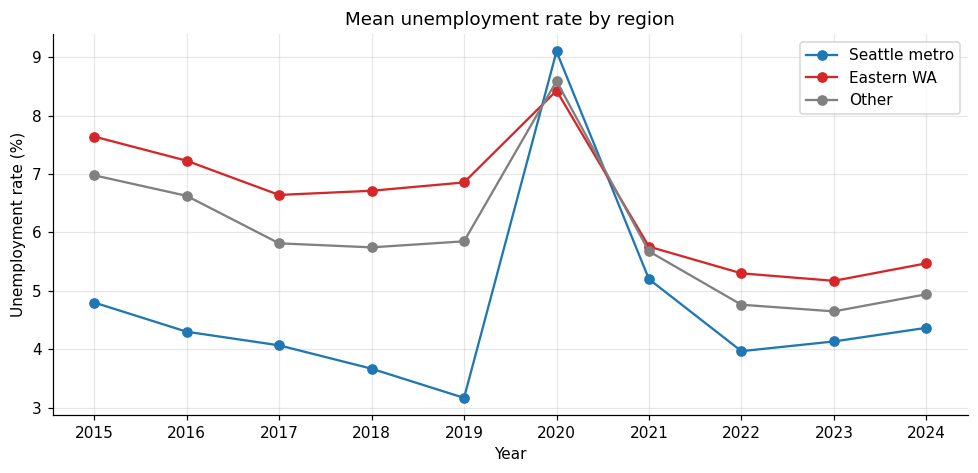

region,Seattle metro,Eastern WA,Other
year,,,
2015,4.80,7.64,6.98
2016,4.30,7.23,6.63
2017,4.07,6.64,5.81
2018,3.67,6.71,5.74
2019,3.17,6.86,5.85
2020,9.10,8.43,8.59
2021,5.20,5.76,5.68
2022,3.97,5.30,4.76
2023,4.13,5.17,4.65


In [17]:
reg = df.pivot_table(index="year", columns="region", values="unemployment_rate", aggfunc="mean")[ORDER]
fig, ax = plt.subplots(figsize=(9, 4.4))
for r in ORDER: ax.plot(reg.index, reg[r], marker="o", color=COLORS[r], label=r)
ax.set(title="Mean unemployment rate by region", xlabel="Year", ylabel="Unemployment rate (%)"); ax.set_xticks(range(2015, 2025)); ax.legend()
plt.tight_layout(); plt.show()
reg.round(2)

Eastern WA counties had the higher rates, 6.6% to 7.6% versus 3.2% to 4.8% for Seattle metro in 2015-2019, a gap of roughly 2.8 to 3.7 points.

Seattle metro jumped from 3.2% (2019) to 9.1% (2020), more than the other groups (Eastern WA: 8.4%, Other: 8.6%). By 2021 the gap was back to about 0.6 points (Seattle 5.2% vs. Eastern 5.8%) and it has remained smaller than before the pandemic (2024: 4.4% vs. 5.5%). The 2020 observations are an influential shock that may distort the regression.

## County-level heatmap

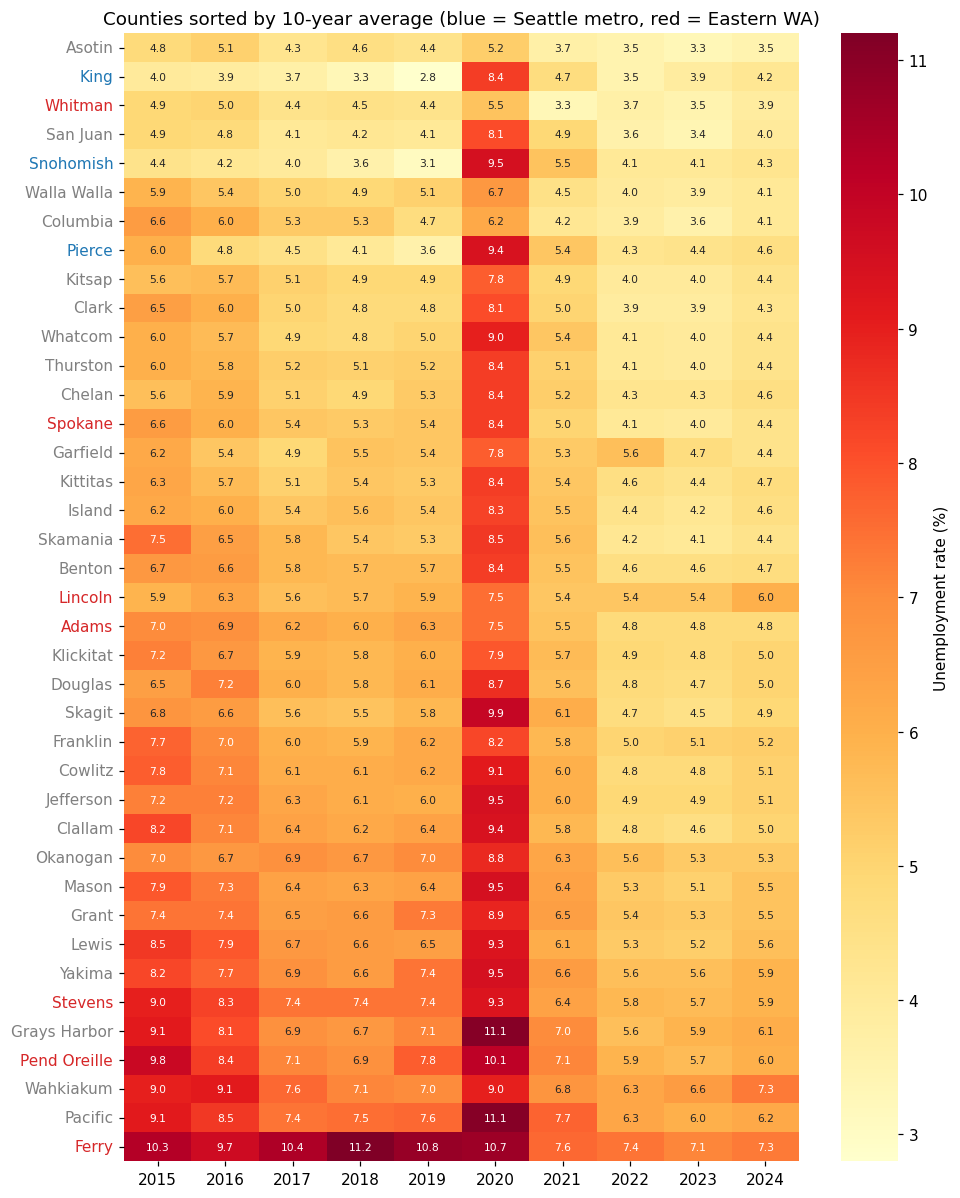

In [20]:
order = wide.mean(axis=1).sort_values().index
fig, ax = plt.subplots(figsize=(9, 11))
sns.heatmap(wide.loc[order], cmap="YlOrRd", annot=True, fmt=".1f", annot_kws={"size": 7}, cbar_kws={"label": "Unemployment rate (%)"}, ax=ax)
region_of = df.drop_duplicates("county").set_index("county")["region"]
for lbl in ax.get_yticklabels(): lbl.set_color(COLORS[region_of[lbl.get_text()]])
ax.set(title="Counties sorted by 10-year average (blue = Seattle metro, red = Eastern WA)", xlabel="", ylabel=""); ax.grid(False)
for lbl in ax.get_yticklabels():
    if region_of[lbl.get_text()] == "Seattle metro": lbl.set_color("C0")
plt.tight_layout(); plt.show()

## Highest and lowest counties; change from 2015 to 2024

In [23]:
summary = pd.DataFrame({"region": region_of, "mean_2015_2024": wide.mean(axis=1), "rate_2015": wide[2015], "rate_2019": wide[2019], "rate_2020": wide[2020], "rate_2024": wide[2024]})
summary["change_2015_2024"] = summary["rate_2024"] - summary["rate_2015"]
summary = summary.sort_values("mean_2015_2024")
print("Lowest 5 counties (10-year average):"); print(summary.head(5).round(2).to_string())
print("\nHighest 5 counties:"); print(summary.tail(5).round(2).to_string())
print("\nLargest declines 2015 -> 2024:"); print(summary.nsmallest(4, "change_2015_2024")[["region", "rate_2015", "rate_2024", "change_2015_2024"]].round(2).to_string())
print("\nLargest increases / smallest declines:"); print(summary.nlargest(4, "change_2015_2024")[["region", "rate_2015", "rate_2024", "change_2015_2024"]].round(2).to_string())

Lowest 5 counties (10-year average):
                  region  mean_2015_2024  rate_2015  rate_2019  rate_2020  rate_2024  change_2015_2024
county                                                                                                
Asotin             Other            4.24        4.8        4.4        5.2        3.5              -1.3
King       Seattle metro            4.24        4.0        2.8        8.4        4.2               0.2
Whitman       Eastern WA            4.31        4.9        4.4        5.5        3.9              -1.0
San Juan           Other            4.61        4.9        4.1        8.1        4.0              -0.9
Snohomish  Seattle metro            4.68        4.4        3.1        9.5        4.3              -0.1

Highest 5 counties:
                  region  mean_2015_2024  rate_2015  rate_2019  rate_2020  rate_2024  change_2015_2024
county                                                                                                
Grays Harbor   

Whitman (4.3%) has one of the lowest 10-year averages in the state, close to King (4.2%), while Ferry (9.3%) has the highest and is the top county in most years. This large within-region spread matters for the proposed t-test and permutation test with only 7 Eastern counties.

## Seattle metro vs. Eastern WA

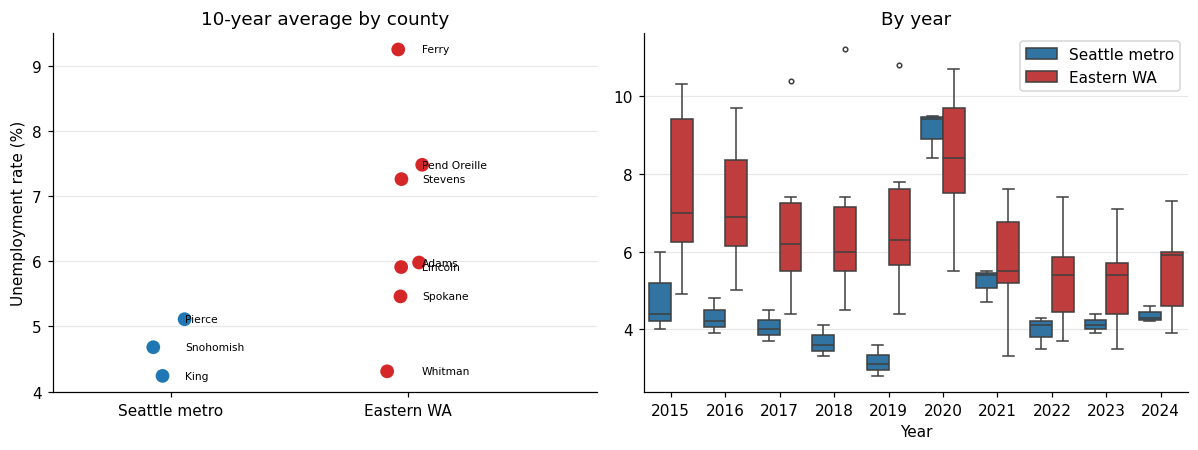

,count,mean,std,min,max
region,,,,,
Eastern WA,70,6.52,1.91,3.3,11.2
Seattle metro,30,4.68,1.65,2.8,9.5


In [26]:
two = df[df["region"].isin(["Seattle metro", "Eastern WA"])]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
cm = two.groupby(["county", "region"])["unemployment_rate"].mean().reset_index()
sns.stripplot(data=cm, x="region", y="unemployment_rate", order=["Seattle metro", "Eastern WA"], hue="region", palette=COLORS, size=9, ax=axes[0], legend=False)
for _, r in cm.iterrows(): axes[0].annotate(r["county"], (["Seattle metro", "Eastern WA"].index(r["region"]) + 0.06, r["unemployment_rate"]), fontsize=7, va="center")
axes[0].set(title="10-year average by county", xlabel="", ylabel="Unemployment rate (%)", xlim=(-0.5, 1.8))
sns.boxplot(data=two, x="year", y="unemployment_rate", hue="region", hue_order=["Seattle metro", "Eastern WA"], palette=COLORS, ax=axes[1], fliersize=3)
axes[1].set(title="By year", xlabel="Year", ylabel=""); axes[1].legend(title="")
plt.tight_layout(); plt.show()
two.groupby("region")["unemployment_rate"].agg(["count", "mean", "std", "min", "max"]).round(2)

## Differences between counties vs. changes over time

Share of variance explained by county averages: 44%

Correlation of county rates across years (persistence):
  2015 vs 2019: 0.89 | 2015 vs 2024: 0.84 | 2019 vs 2020: 0.54 | 2020 vs 2021: 0.89


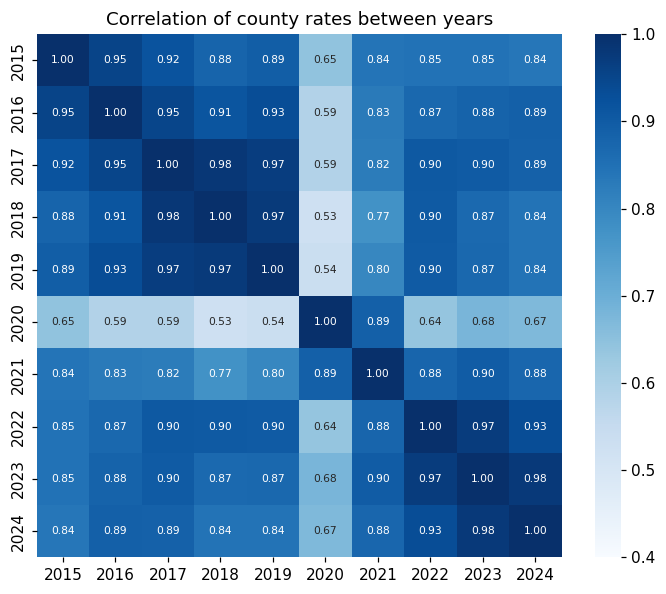

In [28]:
total_var = df["unemployment_rate"].var()
between = df.groupby("county")["unemployment_rate"].mean().var()
print(f"Share of variance explained by county averages: {between / total_var:.0%}")
print("\nCorrelation of county rates across years (persistence):")
print(f"  2015 vs 2019: {wide[2015].corr(wide[2019]):.2f} | 2015 vs 2024: {wide[2015].corr(wide[2024]):.2f} | 2019 vs 2020: {wide[2019].corr(wide[2020]):.2f} | 2020 vs 2021: {wide[2020].corr(wide[2021]):.2f}")
fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(wide.corr(), annot=True, fmt=".2f", cmap="Blues", vmin=0.4, vmax=1, annot_kws={"size": 7}, ax=ax); ax.grid(False)
ax.set(title="Correlation of county rates between years", xlabel="", ylabel=""); plt.tight_layout(); plt.show()

About 44% of the variance is explained by county averages alone, and county rates correlate strongly across years (0.89 for 2015 vs. 2019 and 0.84 for 2015 vs. 2024). Most of the remaining variation comes from time (the 2020 shock).

## Outliers (IQR rule)

In [32]:
q1, q3 = df["unemployment_rate"].quantile([0.25, 0.75]); upper = q3 + 1.5 * (q3 - q1)
print(f"Upper fence: {upper:.2f}% | Lower fence: {q1 - 1.5 * (q3 - q1):.2f}%")
df[df["unemployment_rate"] > upper].sort_values("unemployment_rate", ascending=False)[["county", "region", "year", "unemployment_rate"]]

Upper fence: 10.05% | Lower fence: 1.65%


,county,region,year,unemployment_rate
93,Ferry,Eastern WA,2018,11.2
135,Grays Harbor,Other,2020,11.1
245,Pacific,Other,2020,11.1
94,Ferry,Eastern WA,2019,10.8
95,Ferry,Eastern WA,2020,10.7
92,Ferry,Eastern WA,2017,10.4
90,Ferry,Eastern WA,2015,10.3
255,Pend Oreille,Eastern WA,2020,10.1


The high values (above the 10.05% IQR fence) are mostly Ferry in several years, plus Grays Harbor, Pacific and Pend Oreille in 2020. These look genuine (small, rural economies) and not data errors.